# 06 Final Evaluation


## 1. Load Dataset and Fixed Split


In [33]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\JupyterProject\AIML339_Toxicity"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "labeled_context_1200.parquet"
)

SPLIT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "dataset_split.parquet"
)

df = pd.read_parquet(DATA_PATH)
split_data = pd.read_parquet(SPLIT_PATH)

df = df.merge(
    split_data[
        [
            "annotation_id",
            "split"
        ]
    ],
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

print("Dataset:")
print(df.shape)

print("\nSplit distribution:")
print(
    df["split"].value_counts()
)

Dataset:
(1200, 27)

Split distribution:
split
train         838
validation    183
test          179
Name: count, dtype: int64


## 2. Create Final Test Set


In [34]:
test_df = (
    df[
        df["split"] == "test"
    ]
    .copy()
)

test_df["key"] = (
    test_df["key"]
    .fillna("")
    .astype(str)
)

y_test = (
    test_df["label"]
    .astype(int)
    .to_numpy()
)

print("Test rows:")
print(len(test_df))

print("\nTest label distribution:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)

Test rows:
179

Test label distribution:
label
0    56
1    73
2    50
Name: count, dtype: int64


## 3. Load Text-Only Baseline


In [35]:
import joblib

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
)

baseline_tfidf = joblib.load(
    MODEL_DIR
    / "baseline_tfidf.joblib"
)

baseline_logistic = joblib.load(
    MODEL_DIR
    / "baseline_logistic.joblib"
)

X_test_tfidf = (
    baseline_tfidf.transform(
        test_df["key"]
    )
)

logistic_test_predictions = (
    baseline_logistic.predict(
        X_test_tfidf
    )
)

print("TF-IDF test shape:")
print(X_test_tfidf.shape)

print("\nLogistic predictions:")
print(len(logistic_test_predictions))

TF-IDF test shape:
(179, 397)

Logistic predictions:
179


## 4. Apply Rule-Based Detector


In [36]:
import re

harmful_patterns = [
    r"\bfuck you\b",
    r"\bfuck u\b",
    r"\bkys\b",
    r"\bkill yourself\b",
    r"\bretard\b",
    r"\bretarded\b",
    r"\bidiot\b",
    r"\bstupid\b",
    r"\btrash\b",
    r"\bnoob\b",
    r"\bcunt\b",
    r"\bfaggot\b",
    r"\bnigger\b",
    r"\bnigga\b",
    r"\buninstall\b"
]

emotional_patterns = [
    r"\bwtf\b",
    r"\bfuck\b",
    r"\bshit\b",
    r"\bdamn\b",
    r"\bsad\b",
    r"\bbad\b",
    r"\blost\b",
    r"\blose\b",
    r"\bthrow\b",
    r"\bthrowing\b",
    r"\breport\b",
    r"\bez\b",
    r"\beasy\b"
]


def sensitive_word_detector(message):
    text = str(message).lower()

    for pattern in harmful_patterns:
        if re.search(pattern, text):
            return 2

    for pattern in emotional_patterns:
        if re.search(pattern, text):
            return 1

    return 0


rule_test_predictions = (
    test_df["key"]
    .apply(
        sensitive_word_detector
    )
    .to_numpy()
)

print("Rule predictions:")
print(len(rule_test_predictions))

Rule predictions:
179


## 5. Load Context Model Components


In [37]:
current_tfidf = joblib.load(
    MODEL_DIR / "context_current_tfidf.joblib"
)

current_svd = joblib.load(
    MODEL_DIR / "context_current_svd.joblib"
)

history_tfidf = joblib.load(
    MODEL_DIR / "context_history_tfidf.joblib"
)

history_svd = joblib.load(
    MODEL_DIR / "context_history_svd.joblib"
)

numeric_imputer = joblib.load(
    MODEL_DIR / "context_numeric_imputer.joblib"
)

numeric_scaler = joblib.load(
    MODEL_DIR / "context_numeric_scaler.joblib"
)

print("Context preprocessing components loaded.")

Context preprocessing components loaded.


## 6. Build Test Text Features


In [38]:
history_columns = [
    "prev_message_5",
    "prev_message_4",
    "prev_message_3",
    "prev_message_2",
    "prev_message_1"
]

test_df["history_text"] = (
    test_df[history_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

test_df["current_text"] = (
    test_df["key"]
    .fillna("")
    .astype(str)
)

In [39]:
X_test_current_tfidf = (
    current_tfidf.transform(
        test_df["current_text"]
    )
)

X_test_current = (
    current_svd.transform(
        X_test_current_tfidf
    )
)

X_test_history_tfidf = (
    history_tfidf.transform(
        test_df["history_text"]
    )
)

X_test_history = (
    history_svd.transform(
        X_test_history_tfidf
    )
)

print("Current text:")
print(X_test_current.shape)

print("\nHistory text:")
print(X_test_history.shape)

Current text:
(179, 50)

History text:
(179, 50)


## 7. Build Test Context Features


In [40]:
numeric_features = [
    "messages_last_60s",
    "message_interval",
    "gold",
    "xp",
    "last_hits",
    "seconds_since_teamfight"
]

binary_features = [
    "repeated_message_60s",
    "recent_teamfight_120s",
    "recent_teamfight_loss_120s"
]

X_test_numeric = (
    numeric_imputer.transform(
        test_df[numeric_features]
    )
)

X_test_numeric = (
    numeric_scaler.transform(
        X_test_numeric
    )
)

X_test_binary = (
    test_df[binary_features]
    .astype(float)
    .to_numpy()
)

print("Numeric context:")
print(X_test_numeric.shape)

print("\nBinary context:")
print(X_test_binary.shape)

Numeric context:
(179, 8)

Binary context:
(179, 3)


## 8. Combine Test Features


In [41]:
X_test_context = np.hstack([
    X_test_current,
    X_test_history,
    X_test_numeric,
    X_test_binary
])

print("Context test input:")
print(X_test_context.shape)

Context test input:
(179, 111)


## 9. Load Context-Aware MLP


In [42]:
import torch
import torch.nn as nn

class ContextMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 3)
        )

    def forward(self, x):
        return self.network(x)


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

context_model = ContextMLP(
    X_test_context.shape[1]
)

context_model.load_state_dict(
    torch.load(
        MODEL_DIR / "context_mlp.pt",
        map_location=device
    )
)

context_model = context_model.to(device)
context_model.eval()

print("Context model loaded.")

print("\nInput size:")
print(X_test_context.shape[1])

Context model loaded.

Input size:
111


## 10. Predict with Context Model


In [43]:
X_test_tensor = torch.tensor(
    X_test_context,
    dtype=torch.float32
).to(device)

with torch.no_grad():

    context_outputs = context_model(
        X_test_tensor
    )

    context_test_predictions = (
        torch.argmax(
            context_outputs,
            dim=1
        )
        .cpu()
        .numpy()
    )

print("Context predictions:")
print(len(context_test_predictions))

Context predictions:
179


## 11. Compare Final Test Performance


In [44]:
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

models = {
    "Rule-Based Detector": rule_test_predictions,
    "TF-IDF + Logistic Regression": logistic_test_predictions,
    "Context-Aware MLP": context_test_predictions
}

final_results = []

for model_name, predictions in models.items():

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    final_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

final_results_df = pd.DataFrame(
    final_results
)

display(
    final_results_df.round(4)
)

,Model,Accuracy,Macro F1
0,Rule-Based Detector,0.8101,0.8112
1,TF-IDF + Logistic Regression,0.7821,0.7845
2,Context-Aware MLP,0.7877,0.7889


## 12. Classification Reports


In [45]:
from sklearn.metrics import classification_report

for model_name, predictions in models.items():

    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                "Normal",
                "Limited Emotional",
                "Harmful"
            ],
            digits=3
        )
    )

Rule-Based Detector
                   precision    recall  f1-score   support

           Normal      0.736     0.946     0.828        56
Limited Emotional      0.803     0.781     0.792        73
          Harmful      0.972     0.700     0.814        50

         accuracy                          0.810       179
        macro avg      0.837     0.809     0.811       179
     weighted avg      0.829     0.810     0.809       179

TF-IDF + Logistic Regression
                   precision    recall  f1-score   support

           Normal      0.734     0.839     0.783        56
Limited Emotional      0.794     0.740     0.766        73
          Harmful      0.830     0.780     0.804        50

         accuracy                          0.782       179
        macro avg      0.786     0.786     0.784       179
     weighted avg      0.785     0.782     0.782       179

Context-Aware MLP
                   precision    recall  f1-score   support

           Normal      0.776     0.804   

## 13. Compare Per-Class F1


In [46]:
from sklearn.metrics import precision_recall_fscore_support

class_names = [
    "Normal",
    "Limited Emotional",
    "Harmful"
]

class_results = []

for model_name, predictions in models.items():

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_test,
            predictions,
            labels=[0, 1, 2],
            zero_division=0
        )
    )

    for i, class_name in enumerate(class_names):

        class_results.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1": f1[i],
            "Support": support[i]
        })

class_results_df = pd.DataFrame(
    class_results
)

display(
    class_results_df.round(3)
)

,Model,Class,Precision,Recall,F1,Support
0,Rule-Based Detector,Normal,0.736,0.946,0.828,56
1,Rule-Based Detector,Limited Emotional,0.803,0.781,0.792,73
2,Rule-Based Detector,Harmful,0.972,0.700,0.814,50
3,TF-IDF + Logistic Regression,Normal,0.734,0.839,0.783,56
4,TF-IDF + Logistic Regression,Limited Emotional,0.794,0.740,0.766,73
5,TF-IDF + Logistic Regression,Harmful,0.830,0.780,0.804,50
6,Context-Aware MLP,Normal,0.776,0.804,0.789,56
7,Context-Aware MLP,Limited Emotional,0.756,0.808,0.781,73
8,Context-Aware MLP,Harmful,0.860,0.740,0.796,50


## 14. Final Confusion Matrices


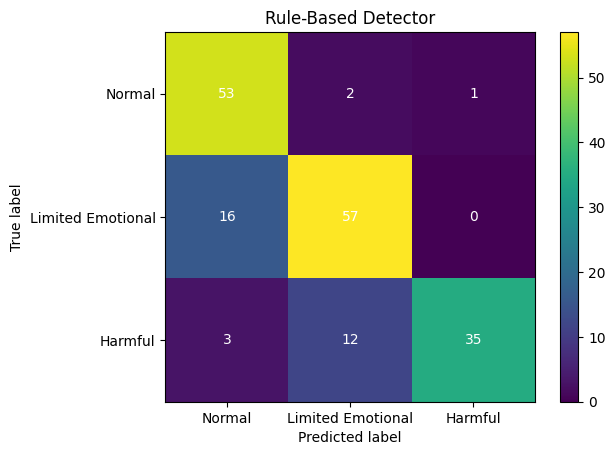

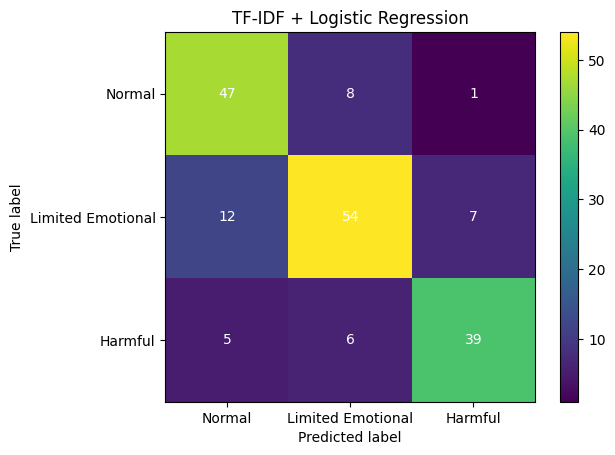

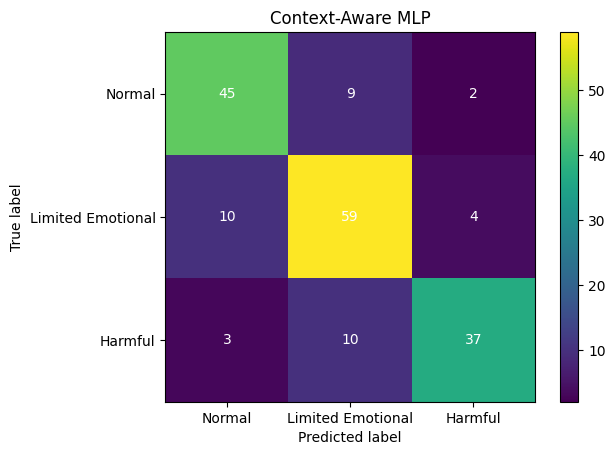

In [81]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

for model_name, predictions in models.items():

    cm = confusion_matrix(
        y_test,
        predictions
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Normal",
            "Limited Emotional",
            "Harmful"
        ]
    )

    disp.plot()
    for text in disp.text_.ravel():
        text.set_color("white")

    plt.title(model_name)

    plt.show()

## 15. Save Final Evaluation Results


In [48]:
FINAL_RESULTS_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_results.csv"
)

final_results_df.to_csv(
    FINAL_RESULTS_PATH,
    index=False
)

print("Saved to:")
print(FINAL_RESULTS_PATH)

display(
    final_results_df.round(4)
)

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\final_test_results.csv


,Model,Accuracy,Macro F1
0,Rule-Based Detector,0.8101,0.8112
1,TF-IDF + Logistic Regression,0.7821,0.7845
2,Context-Aware MLP,0.7877,0.7889


## 16. Save Test Predictions


In [49]:
test_predictions = test_df[
    [
        "annotation_id",
        "match_id",
        "key",
        "label"
    ]
].copy()

test_predictions[
    "rule_prediction"
] = rule_test_predictions

test_predictions[
    "logistic_prediction"
] = logistic_test_predictions

test_predictions[
    "context_prediction"
] = context_test_predictions

TEST_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_predictions.parquet"
)

test_predictions.to_parquet(
    TEST_PREDICTIONS_PATH,
    index=False
)

print("Saved to:")
print(TEST_PREDICTIONS_PATH)

print("\nRows:")
print(len(test_predictions))

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\final_test_predictions.parquet

Rows:
179


## 17. Compare Logistic and Context Errors


In [50]:
comparison_errors = test_predictions.copy()

comparison_errors[
    "logistic_correct"
] = (
    comparison_errors["logistic_prediction"]
    == comparison_errors["label"]
)

comparison_errors[
    "context_correct"
] = (
    comparison_errors["context_prediction"]
    == comparison_errors["label"]
)

context_fixed = comparison_errors[
    (~comparison_errors["logistic_correct"])
    &
    (comparison_errors["context_correct"])
]

context_hurt = comparison_errors[
    (comparison_errors["logistic_correct"])
    &
    (~comparison_errors["context_correct"])
]

print("Errors fixed by Context:")
print(len(context_fixed))

print("\nCorrect predictions changed to errors:")
print(len(context_hurt))

Errors fixed by Context:
14

Correct predictions changed to errors:
13


In [51]:
display(
    context_fixed[
        [
            "key",
            "label",
            "logistic_prediction",
            "context_prediction"
        ]
    ].head(30)
)

display(
    context_hurt[
        [
            "key",
            "label",
            "logistic_prediction",
            "context_prediction"
        ]
    ].head(30)
)

,key,label,logistic_prediction,context_prediction
556,say the one got fuck by puck,1,2,1
602,commend me for carrying trash blood,2,0,2
637,sorry all guy bad server,1,0,1
772,bg naabs ;),2,0,2
792,or shut the fuck up,2,1,2
830,why wont you rupture me again,1,0,1
850,even me,0,1,0
861,u lil shit,2,1,2
975,cant do shit .,1,2,1
1016,i kill sd,0,1,0


,key,label,logistic_prediction,context_prediction
0,man ur life must be shit,2,2,1
99,fuck yourself,2,2,1
116,AW,0,0,1
251,why are you not ending,1,1,0
378,peace of shit,2,2,1
395,why dont stay?,0,0,1
625,thank wr,0,0,1
626,fuck u jugg,2,2,1
706,are totally shit,2,2,1
832,U CAN HIUT,0,0,2


## 18. Define Ablation Feature Groups


In [52]:
behaviour_numeric_features = [
    "messages_last_60s",
    "message_interval"
]

behaviour_binary_features = [
    "repeated_message_60s"
]

match_numeric_features = [
    "gold",
    "xp",
    "last_hits",
    "seconds_since_teamfight"
]

match_binary_features = [
    "recent_teamfight_120s",
    "recent_teamfight_loss_120s"
]

print("Behaviour numeric:")
print(behaviour_numeric_features)

print("\nBehaviour binary:")
print(behaviour_binary_features)

print("\nMatch numeric:")
print(match_numeric_features)

print("\nMatch binary:")
print(match_binary_features)

Behaviour numeric:
['messages_last_60s', 'message_interval']

Behaviour binary:
['repeated_message_60s']

Match numeric:
['gold', 'xp', 'last_hits', 'seconds_since_teamfight']

Match binary:
['recent_teamfight_120s', 'recent_teamfight_loss_120s']


### 18.1 Prepare Train and Validation Sets


In [53]:
train_df = (
    df[
        df["split"] == "train"
    ]
    .copy()
)

val_df = (
    df[
        df["split"] == "validation"
    ]
    .copy()
)

test_df = (
    df[
        df["split"] == "test"
    ]
    .copy()
)

print("Train:")
print(len(train_df))

print("\nValidation:")
print(len(val_df))

print("\nTest:")
print(len(test_df))

Train:
838

Validation:
183

Test:
179


## 19. Prepare Behaviour Features


In [54]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

behaviour_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_train_behaviour_numeric = (
    behaviour_imputer.fit_transform(
        train_df[behaviour_numeric_features]
    )
)

X_val_behaviour_numeric = (
    behaviour_imputer.transform(
        val_df[behaviour_numeric_features]
    )
)

X_test_behaviour_numeric = (
    behaviour_imputer.transform(
        test_df[behaviour_numeric_features]
    )
)

behaviour_scaler = StandardScaler()

X_train_behaviour_numeric = (
    behaviour_scaler.fit_transform(
        X_train_behaviour_numeric
    )
)

X_val_behaviour_numeric = (
    behaviour_scaler.transform(
        X_val_behaviour_numeric
    )
)

X_test_behaviour_numeric = (
    behaviour_scaler.transform(
        X_test_behaviour_numeric
    )
)

X_train_behaviour_binary = (
    train_df[behaviour_binary_features]
    .astype(float)
    .to_numpy()
)

X_val_behaviour_binary = (
    val_df[behaviour_binary_features]
    .astype(float)
    .to_numpy()
)

X_test_behaviour_binary = (
    test_df[behaviour_binary_features]
    .astype(float)
    .to_numpy()
)

X_train_behaviour = np.hstack([
    X_train_behaviour_numeric,
    X_train_behaviour_binary
])

X_val_behaviour = np.hstack([
    X_val_behaviour_numeric,
    X_val_behaviour_binary
])

X_test_behaviour = np.hstack([
    X_test_behaviour_numeric,
    X_test_behaviour_binary
])

print("Behaviour feature shape:")
print(X_train_behaviour.shape)

Behaviour feature shape:
(838, 4)


## 20. Prepare Match Features


In [55]:
match_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

X_train_match_numeric = (
    match_imputer.fit_transform(
        train_df[match_numeric_features]
    )
)

X_val_match_numeric = (
    match_imputer.transform(
        val_df[match_numeric_features]
    )
)

X_test_match_numeric = (
    match_imputer.transform(
        test_df[match_numeric_features]
    )
)

match_scaler = StandardScaler()

X_train_match_numeric = (
    match_scaler.fit_transform(
        X_train_match_numeric
    )
)

X_val_match_numeric = (
    match_scaler.transform(
        X_val_match_numeric
    )
)

X_test_match_numeric = (
    match_scaler.transform(
        X_test_match_numeric
    )
)

X_train_match_binary = (
    train_df[match_binary_features]
    .astype(float)
    .to_numpy()
)

X_val_match_binary = (
    val_df[match_binary_features]
    .astype(float)
    .to_numpy()
)

X_test_match_binary = (
    test_df[match_binary_features]
    .astype(float)
    .to_numpy()
)

X_train_match = np.hstack([
    X_train_match_numeric,
    X_train_match_binary
])

X_val_match = np.hstack([
    X_val_match_numeric,
    X_val_match_binary
])

X_test_match = np.hstack([
    X_test_match_numeric,
    X_test_match_binary
])

print("Match feature shape:")
print(X_train_match.shape)

Match feature shape:
(838, 7)


## 21. Rebuild Text Features for Ablation


In [56]:
for data in [
    train_df,
    val_df,
    test_df
]:
    data["current_text"] = (
        data["key"]
        .fillna("")
        .astype(str)
    )

    data["history_text"] = (
        data[history_columns]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
        .str.strip()
    )

In [57]:
X_train_current = current_svd.transform(
    current_tfidf.transform(
        train_df["current_text"]
    )
)

X_val_current = current_svd.transform(
    current_tfidf.transform(
        val_df["current_text"]
    )
)

X_test_current = current_svd.transform(
    current_tfidf.transform(
        test_df["current_text"]
    )
)


X_train_history = history_svd.transform(
    history_tfidf.transform(
        train_df["history_text"]
    )
)

X_val_history = history_svd.transform(
    history_tfidf.transform(
        val_df["history_text"]
    )
)

X_test_history = history_svd.transform(
    history_tfidf.transform(
        test_df["history_text"]
    )
)

print("Current text:")
print(
    X_train_current.shape,
    X_val_current.shape,
    X_test_current.shape
)

print("\nHistory text:")
print(
    X_train_history.shape,
    X_val_history.shape,
    X_test_history.shape
)

Current text:
(838, 50) (183, 50) (179, 50)

History text:
(838, 50) (183, 50) (179, 50)


## 22. Prepare Ablation Labels


In [58]:
y_train = (
    train_df["label"]
    .astype(int)
    .to_numpy()
)

y_val = (
    val_df["label"]
    .astype(int)
    .to_numpy()
)

y_test = (
    test_df["label"]
    .astype(int)
    .to_numpy()
)

print("Train labels:")
print(y_train.shape)

print("\nValidation labels:")
print(y_val.shape)

print("\nTest labels:")
print(y_test.shape)

Train labels:
(838,)

Validation labels:
(183,)

Test labels:
(179,)


## 23. Build Ablation Configurations


In [59]:
ablation_features = {
    "Current Text": (
        X_train_current,
        X_val_current,
        X_test_current
    ),

    "Current + History": (
        np.hstack([
            X_train_current,
            X_train_history
        ]),
        np.hstack([
            X_val_current,
            X_val_history
        ]),
        np.hstack([
            X_test_current,
            X_test_history
        ])
    ),

    "Current + History + Behaviour": (
        np.hstack([
            X_train_current,
            X_train_history,
            X_train_behaviour
        ]),
        np.hstack([
            X_val_current,
            X_val_history,
            X_val_behaviour
        ]),
        np.hstack([
            X_test_current,
            X_test_history,
            X_test_behaviour
        ])
    ),

    "Full Context": (
        np.hstack([
            X_train_current,
            X_train_history,
            X_train_behaviour,
            X_train_match
        ]),
        np.hstack([
            X_val_current,
            X_val_history,
            X_val_behaviour,
            X_val_match
        ]),
        np.hstack([
            X_test_current,
            X_test_history,
            X_test_behaviour,
            X_test_match
        ])
    )
}

for name, (
    X_train_ab,
    X_val_ab,
    X_test_ab
) in ablation_features.items():

    print(
        name,
        X_train_ab.shape,
        X_val_ab.shape,
        X_test_ab.shape
    )

Current Text (838, 50) (183, 50) (179, 50)
Current + History (838, 100) (183, 100) (179, 100)
Current + History + Behaviour (838, 104) (183, 104) (179, 104)
Full Context (838, 111) (183, 111) (179, 111)


## 24. Define Ablation Training Function


In [60]:
import copy
import torch
import torch.nn as nn

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

from sklearn.metrics import f1_score


class AblationMLP(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 3)
        )

    def forward(self, x):
        return self.network(x)

In [61]:
def train_ablation_model(
    X_train,
    X_val,
    X_test,
    y_train,
    y_val,
    y_test,
    epochs=50,
    seed=339
):

    torch.manual_seed(seed)
    np.random.seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = AblationMLP(
        X_train.shape[1]
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    train_dataset = TensorDataset(
        torch.tensor(
            X_train,
            dtype=torch.float32
        ),
        torch.tensor(
            y_train,
            dtype=torch.long
        )
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    X_val_tensor = torch.tensor(
        X_val,
        dtype=torch.float32
    ).to(device)

    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    ).to(device)

    best_val_f1 = 0
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):

        model.train()

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            loss.backward()
            optimizer.step()

        model.eval()

        with torch.no_grad():

            val_predictions = (
                torch.argmax(
                    model(X_val_tensor),
                    dim=1
                )
                .cpu()
                .numpy()
            )

        val_f1 = f1_score(
            y_val,
            val_predictions,
            average="macro"
        )

        if val_f1 > best_val_f1:

            best_val_f1 = val_f1
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(
        best_state
    )

    model.eval()

    with torch.no_grad():

        test_predictions = (
            torch.argmax(
                model(X_test_tensor),
                dim=1
            )
            .cpu()
            .numpy()
        )

    test_f1 = f1_score(
        y_test,
        test_predictions,
        average="macro"
    )

    return {
        "best_epoch": best_epoch,
        "validation_macro_f1": best_val_f1,
        "test_macro_f1": test_f1
    }

## 24.1 Test Different Random Seeds


In [62]:
test_seeds = [339, 340]

for seed in test_seeds:

    print("Seed:", seed)

    result = train_ablation_model(
        ablation_features["Current Text"][0],
        ablation_features["Current Text"][1],
        ablation_features["Current Text"][2],
        y_train,
        y_val,
        y_test,
        seed=seed
    )

    print(
        "Best Epoch:",
        result["best_epoch"]
    )

    print(
        "Validation Macro-F1:",
        round(result["validation_macro_f1"], 4)
    )

    print(
        "Test Macro-F1:",
        round(result["test_macro_f1"], 4)
    )

    print()

Seed: 339
Best Epoch: 46
Validation Macro-F1: 0.8416
Test Macro-F1: 0.8224

Seed: 340
Best Epoch: 49
Validation Macro-F1: 0.8459
Test Macro-F1: 0.8166



## 24.2 Repeated Ablation Experiments


In [63]:
repeated_seeds = list(range(339, 369))

repeated_results = []

for name, (
    X_train_ab,
    X_val_ab,
    X_test_ab
) in ablation_features.items():

    print("\nConfiguration:", name)

    for run_number, seed in enumerate(
        repeated_seeds,
        start=1
    ):

        result = train_ablation_model(
            X_train_ab,
            X_val_ab,
            X_test_ab,
            y_train,
            y_val,
            y_test,
            seed=seed
        )

        repeated_results.append({
            "Configuration": name,
            "Seed": seed,
            "Best Epoch": result["best_epoch"],
            "Validation Macro F1":
                result["validation_macro_f1"],
            "Test Macro F1":
                result["test_macro_f1"]
        })

        print(
            f"{run_number:02d}/30",
            f"Seed={seed}",
            f"Val={result['validation_macro_f1']:.4f}",
            f"Test={result['test_macro_f1']:.4f}",
            f"Epoch={result['best_epoch']}"
        )


Configuration: Current Text
01/30 Seed=339 Val=0.8416 Test=0.8224 Epoch=46
02/30 Seed=340 Val=0.8459 Test=0.8166 Epoch=49
03/30 Seed=341 Val=0.8370 Test=0.8287 Epoch=41
04/30 Seed=342 Val=0.8312 Test=0.8111 Epoch=44
05/30 Seed=343 Val=0.8429 Test=0.8229 Epoch=48
06/30 Seed=344 Val=0.8357 Test=0.8129 Epoch=13
07/30 Seed=345 Val=0.8358 Test=0.8287 Epoch=50
08/30 Seed=346 Val=0.8368 Test=0.8125 Epoch=50
09/30 Seed=347 Val=0.8366 Test=0.8046 Epoch=42
10/30 Seed=348 Val=0.8370 Test=0.8287 Epoch=49
11/30 Seed=349 Val=0.8420 Test=0.8287 Epoch=50
12/30 Seed=350 Val=0.8418 Test=0.8132 Epoch=37
13/30 Seed=351 Val=0.8370 Test=0.8119 Epoch=42
14/30 Seed=352 Val=0.8370 Test=0.8177 Epoch=37
15/30 Seed=353 Val=0.8310 Test=0.8286 Epoch=48
16/30 Seed=354 Val=0.8307 Test=0.8116 Epoch=35
17/30 Seed=355 Val=0.8420 Test=0.8228 Epoch=46
18/30 Seed=356 Val=0.8370 Test=0.8177 Epoch=47
19/30 Seed=357 Val=0.8310 Test=0.8227 Epoch=40
20/30 Seed=358 Val=0.8428 Test=0.8175 Epoch=41
21/30 Seed=359 Val=0.8379 Test=

,Configuration,Runs,Validation_Macro_F1_Mean,Validation_Macro_F1_Std,Test_Macro_F1_Mean,Test_Macro_F1_Std,Mean_Best_Epoch
0,Current + History,30,0.840589,0.006540,0.791303,0.009628,39.233333
1,Current + History + Behaviour,30,0.829611,0.006824,0.781068,0.013363,20.366667
2,Current Text,30,0.836770,0.004333,0.818009,0.007518,42.100000
3,Full Context,30,0.807882,0.009052,0.789821,0.014347,27.633333


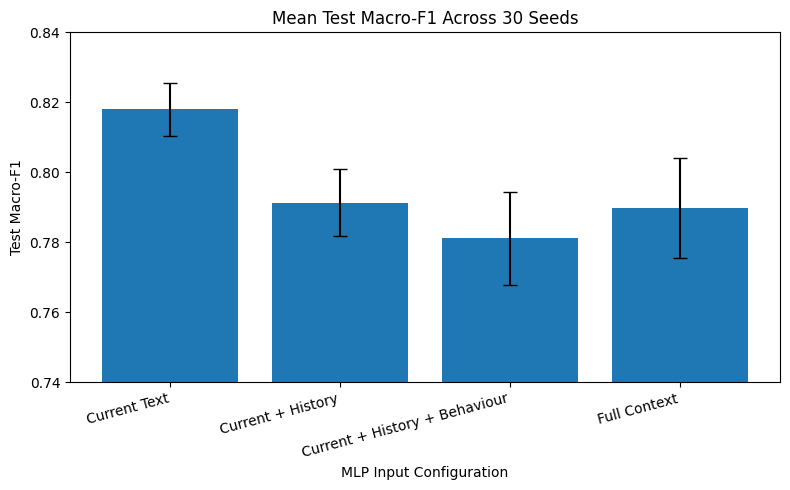

Saved figure to:
D:\JupyterProject\AIML339_Toxicity\data\processed\figure_ablation_results.png


In [76]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Project path
PROJECT_ROOT = Path(
    r"D:\JupyterProject\AIML339_Toxicity"
)

summary_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "repeated_ablation_summary.csv"
)

summary_df = pd.read_csv(summary_path)

display(summary_df)

# Order used in the report
plot_order = [
    "Current Text",
    "Current + History",
    "Current + History + Behaviour",
    "Full Context"
]

plot_df = (
    summary_df
    .set_index("Configuration")
    .loc[plot_order]
    .reset_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    plot_df["Configuration"],
    plot_df["Test_Macro_F1_Mean"],
    yerr=plot_df["Test_Macro_F1_Std"],
    capsize=5
)

plt.ylabel("Test Macro-F1")
plt.xlabel("MLP Input Configuration")
plt.title("Mean Test Macro-F1 Across 30 Seeds")

plt.ylim(0.74, 0.84)
plt.xticks(rotation=15, ha="right")

plt.tight_layout()

figure_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "figure_ablation_results.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved figure to:")
print(figure_path)

## 24.3 Summarise Repeated Results


In [64]:
repeated_results_df = pd.DataFrame(
    repeated_results
)

repeated_summary = (
    repeated_results_df
    .groupby("Configuration")
    .agg(
        Runs=("Seed", "count"),
        Validation_Macro_F1_Mean=(
            "Validation Macro F1",
            "mean"
        ),
        Validation_Macro_F1_Std=(
            "Validation Macro F1",
            "std"
        ),
        Test_Macro_F1_Mean=(
            "Test Macro F1",
            "mean"
        ),
        Test_Macro_F1_Std=(
            "Test Macro F1",
            "std"
        ),
        Mean_Best_Epoch=(
            "Best Epoch",
            "mean"
        )
    )
    .reset_index()
)

display(
    repeated_summary.round(4)
)

,Configuration,Runs,Validation_Macro_F1_Mean,Validation_Macro_F1_Std,Test_Macro_F1_Mean,Test_Macro_F1_Std,Mean_Best_Epoch
0,Current + History,30,0.8406,0.0065,0.7913,0.0096,39.2333
1,Current + History + Behaviour,30,0.8296,0.0068,0.7811,0.0134,20.3667
2,Current Text,30,0.8368,0.0043,0.8180,0.0075,42.1000
3,Full Context,30,0.8079,0.0091,0.7898,0.0143,27.6333


## 24.4 Save Repeated Experiment Results


In [65]:
repeated_results_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "repeated_ablation_results.csv"
)

repeated_summary_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "repeated_ablation_summary.csv"
)

repeated_results_df.to_csv(
    repeated_results_path,
    index=False
)

repeated_summary.to_csv(
    repeated_summary_path,
    index=False
)

print("Saved:", repeated_results_path)
print("Saved:", repeated_summary_path)

print()
print("Raw results:", repeated_results_df.shape)
print("Summary:", repeated_summary.shape)

Saved: D:\JupyterProject\AIML339_Toxicity\data\processed\repeated_ablation_results.csv
Saved: D:\JupyterProject\AIML339_Toxicity\data\processed\repeated_ablation_summary.csv

Raw results: (120, 5)
Summary: (4, 7)


,Configuration,Runs,Validation_Macro_F1_Mean,Validation_Macro_F1_Std,Test_Macro_F1_Mean,Test_Macro_F1_Std,Mean_Best_Epoch
0,Current + History,30,0.840589,0.006540,0.791303,0.009628,39.233333
1,Current + History + Behaviour,30,0.829611,0.006824,0.781068,0.013363,20.366667
2,Current Text,30,0.836770,0.004333,0.818009,0.007518,42.100000
3,Full Context,30,0.807882,0.009052,0.789821,0.014347,27.633333


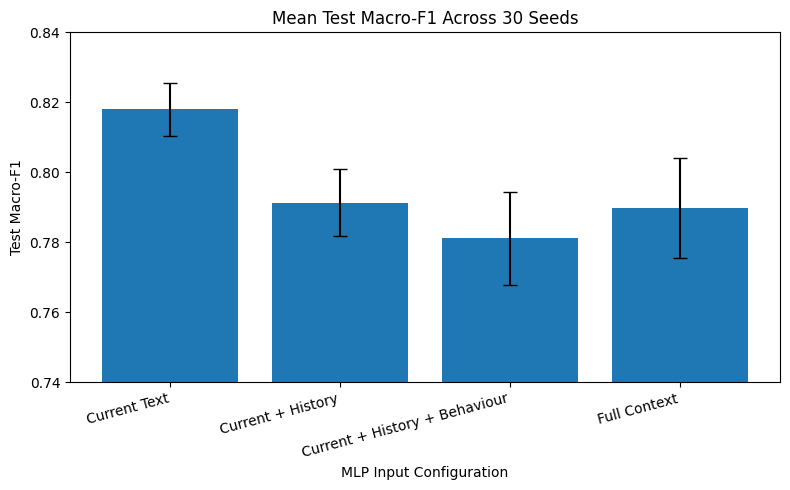

Saved figure to:
D:\JupyterProject\AIML339_Toxicity\data\processed\figure_ablation_results.png


In [66]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Project path
PROJECT_ROOT = Path(
    r"D:\JupyterProject\AIML339_Toxicity"
)

summary_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "repeated_ablation_summary.csv"
)

summary_df = pd.read_csv(summary_path)

display(summary_df)

# Order used in the report
plot_order = [
    "Current Text",
    "Current + History",
    "Current + History + Behaviour",
    "Full Context"
]

plot_df = (
    summary_df
    .set_index("Configuration")
    .loc[plot_order]
    .reset_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    plot_df["Configuration"],
    plot_df["Test_Macro_F1_Mean"],
    yerr=plot_df["Test_Macro_F1_Std"],
    capsize=5
)

plt.ylabel("Test Macro-F1")
plt.xlabel("MLP Input Configuration")
plt.title("Mean Test Macro-F1 Across 30 Seeds")

plt.ylim(0.74, 0.84)
plt.xticks(rotation=15, ha="right")

plt.tight_layout()

figure_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "figure_ablation_results.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved figure to:")
print(figure_path)

## 24.5 Statistical Comparison


In [67]:
from scipy.stats import wilcoxon

paired_results = (
    repeated_results_df
    .pivot(
        index="Seed",
        columns="Configuration",
        values="Test Macro F1"
    )
    .sort_index()
)

display(
    paired_results.head()
)

comparisons = [
    "Current + History",
    "Current + History + Behaviour",
    "Full Context"
]

statistical_results = []

for comparison in comparisons:

    current_scores = paired_results[
        "Current Text"
    ]

    comparison_scores = paired_results[
        comparison
    ]

    statistic, p_value = wilcoxon(
        current_scores,
        comparison_scores,
        alternative="two-sided"
    )

    mean_difference = (
        current_scores - comparison_scores
    ).mean()

    statistical_results.append({
        "Comparison":
            f"Current Text vs {comparison}",
        "Mean Difference":
            mean_difference,
        "Wilcoxon Statistic":
            statistic,
        "Raw p-value":
            p_value
    })

statistical_results_df = pd.DataFrame(
    statistical_results
)

statistical_results_df

Configuration,Current + History,Current + History + Behaviour,Current Text,Full Context
Seed,,,,
339,0.811696,0.789409,0.822370,0.775805
340,0.790677,0.800775,0.816640,0.789200
341,0.790984,0.772013,0.828698,0.782368
342,0.800813,0.765873,0.811077,0.779265
343,0.784417,0.778622,0.822925,0.795343


,Comparison,Mean Difference,Wilcoxon Statistic,Raw p-value
0,Current Text vs Current + History,0.026706,7.0,3.539026e-08
1,Current Text vs Current + History + Behaviour,0.036940,0.0,1.862645e-09
2,Current Text vs Full Context,0.028188,15.0,2.551824e-07


## 24.6 Multiple Comparison Correction


In [68]:
from statsmodels.stats.multitest import multipletests

reject, adjusted_p_values, _, _ = multipletests(
    statistical_results_df["Raw p-value"],
    alpha=0.05,
    method="holm"
)

statistical_results_df[
    "Holm Adjusted p-value"
] = adjusted_p_values

statistical_results_df[
    "Significant"
] = reject

display(
    statistical_results_df
)

,Comparison,Mean Difference,Wilcoxon Statistic,Raw p-value,Holm Adjusted p-value,Significant
0,Current Text vs Current + History,0.026706,7.0,3.539026e-08,7.078052e-08,True
1,Current Text vs Current + History + Behaviour,0.036940,0.0,1.862645e-09,5.587935e-09,True
2,Current Text vs Full Context,0.028188,15.0,2.551824e-07,2.551824e-07,True


## 24.7 Save Statistical Results


In [69]:
statistical_results_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "repeated_ablation_statistics.csv"
)

statistical_results_df.to_csv(
    statistical_results_path,
    index=False
)

print(
    "Saved:",
    statistical_results_path
)

Saved: D:\JupyterProject\AIML339_Toxicity\data\processed\repeated_ablation_statistics.csv


## 24.8 Repeated Experiment Interpretation


## 25. Run Ablation Study


In [70]:
ablation_results = []

for name, (
    X_train_ab,
    X_val_ab,
    X_test_ab
) in ablation_features.items():

    print("Training:", name)

    result = train_ablation_model(
        X_train_ab,
        X_val_ab,
        X_test_ab,
        y_train,
        y_val,
        y_test
    )

    ablation_results.append({
        "Configuration": name,
        "Input Dimensions": X_train_ab.shape[1],
        "Best Epoch": result["best_epoch"],
        "Validation Macro F1":
            result["validation_macro_f1"],
        "Test Macro F1":
            result["test_macro_f1"]
    })

    print(
        "Validation Macro-F1:",
        round(
            result["validation_macro_f1"],
            4
        )
    )

    print(
        "Test Macro-F1:",
        round(
            result["test_macro_f1"],
            4
        )
    )

    print()

Training: Current Text
Validation Macro-F1: 0.8416
Test Macro-F1: 0.8224

Training: Current + History
Validation Macro-F1: 0.8434
Test Macro-F1: 0.8117

Training: Current + History + Behaviour
Validation Macro-F1: 0.811
Test Macro-F1: 0.7894

Training: Full Context
Validation Macro-F1: 0.8089
Test Macro-F1: 0.7758



## 26. Show Ablation Results


In [71]:
ablation_results_df = pd.DataFrame(
    ablation_results
)

display(
    ablation_results_df.round(4)
)

,Configuration,Input Dimensions,Best Epoch,Validation Macro F1,Test Macro F1
0,Current Text,50,46,0.8416,0.8224
1,Current + History,100,49,0.8434,0.8117
2,Current + History + Behaviour,104,20,0.8110,0.7894
3,Full Context,111,25,0.8089,0.7758


## 27. Show Complete Ablation Results


In [72]:
print(
    ablation_results_df[
        [
            "Configuration",
            "Input Dimensions",
            "Best Epoch",
            "Validation Macro F1",
            "Test Macro F1"
        ]
    ].to_string(index=False)
)

                Configuration  Input Dimensions  Best Epoch  Validation Macro F1  Test Macro F1
                 Current Text                50          46             0.841631       0.822370
            Current + History               100          49             0.843390       0.811696
Current + History + Behaviour               104          20             0.811046       0.789409
                 Full Context               111          25             0.808946       0.775805


## 28. Save Ablation Results


In [73]:
ABLATION_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "ablation_results.csv"
)

ablation_results_df.to_csv(
    ABLATION_PATH,
    index=False
)

print("Saved to:")
print(ABLATION_PATH)

Saved to:
D:\JupyterProject\AIML339_Toxicity\data\processed\ablation_results.csv


## 29. Print Final Ablation Results


In [74]:
print(
    ablation_results_df[
        [
            "Configuration",
            "Input Dimensions",
            "Best Epoch",
            "Validation Macro F1",
            "Test Macro F1"
        ]
    ].round(4).to_string(index=False)
)

                Configuration  Input Dimensions  Best Epoch  Validation Macro F1  Test Macro F1
                 Current Text                50          46               0.8416         0.8224
            Current + History               100          49               0.8434         0.8117
Current + History + Behaviour               104          20               0.8110         0.7894
                 Full Context               111          25               0.8089         0.7758


## 30. Final Output Check


In [75]:
output_files = [
    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_results.csv",

    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_predictions.parquet",

    PROJECT_ROOT
    / "data"
    / "processed"
    / "ablation_results.csv"
]

for path in output_files:
    print(
        path.name,
        "->",
        path.exists()
    )

final_test_results.csv -> True
final_test_predictions.parquet -> True
ablation_results.csv -> True


In [83]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\JupyterProject\AIML339_Toxicity"
)

summary_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "repeated_ablation_summary.csv"
)

summary_df = pd.read_csv(summary_path)

input_dimensions = {
    "Current Text": 50,
    "Current + History": 100,
    "Current + History + Behaviour": 104,
    "Full Context": 111
}

plot_order = [
    "Current Text",
    "Current + History",
    "Current + History + Behaviour",
    "Full Context"
]

ablation_table = summary_df[
    [
        "Configuration",
        "Test_Macro_F1_Mean",
        "Test_Macro_F1_Std"
    ]
].copy()

ablation_table["Input Dimension"] = (
    ablation_table["Configuration"]
    .map(input_dimensions)
)

ablation_table["Test Macro-F1"] = (
    ablation_table.apply(
        lambda row:
        f"{row['Test_Macro_F1_Mean']:.4f} ± "
        f"{row['Test_Macro_F1_Std']:.4f}",
        axis=1
    )
)

ablation_table = (
    ablation_table
    .set_index("Configuration")
    .loc[plot_order]
    .reset_index()
)

ablation_table = ablation_table[
    [
        "Configuration",
        "Input Dimension",
        "Test Macro-F1"
    ]
]

display(ablation_table)

output_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "report_ablation_table.csv"
)

ablation_table.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

,Configuration,Input Dimension,Test Macro-F1
0,Current Text,50,0.8180 ± 0.0075
1,Current + History,100,0.7913 ± 0.0096
2,Current + History + Behaviour,104,0.7811 ± 0.0134
3,Full Context,111,0.7898 ± 0.0143


Saved: D:\JupyterProject\AIML339_Toxicity\data\processed\report_ablation_table.csv


In [84]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\JupyterProject\AIML339_Toxicity"
)

predictions_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "final_test_predictions.parquet"
)

test_predictions = pd.read_parquet(
    predictions_path
)

baseline_models = {
    "Rule-Based Detector":
        test_predictions["rule_prediction"],

    "TF-IDF + Logistic Regression":
        test_predictions["logistic_prediction"]
}

class_names = [
    "Normal",
    "Limited Emotional",
    "Harmful"
]

baseline_rows = []

for model_name, predictions in baseline_models.items():

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            test_predictions["label"],
            predictions,
            labels=[0, 1, 2],
            zero_division=0
        )
    )

    for i, class_name in enumerate(class_names):

        baseline_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1": f1[i]
        })

baseline_metrics_table = pd.DataFrame(
    baseline_rows
)

baseline_metrics_table[
    ["Precision", "Recall", "F1"]
] = baseline_metrics_table[
    ["Precision", "Recall", "F1"]
].round(3)

display(baseline_metrics_table)

output_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "report_baseline_per_class_metrics.csv"
)

baseline_metrics_table.to_csv(
    output_path,
    index=False
)

print("Saved:", output_path)

,Model,Class,Precision,Recall,F1
0,Rule-Based Detector,Normal,0.736,0.946,0.828
1,Rule-Based Detector,Limited Emotional,0.803,0.781,0.792
2,Rule-Based Detector,Harmful,0.972,0.700,0.814
3,TF-IDF + Logistic Regression,Normal,0.734,0.839,0.783
4,TF-IDF + Logistic Regression,Limited Emotional,0.794,0.740,0.766
5,TF-IDF + Logistic Regression,Harmful,0.830,0.780,0.804


Saved: D:\JupyterProject\AIML339_Toxicity\data\processed\report_baseline_per_class_metrics.csv
